## Wstęp do Uczenia Maszynowego

#### Laboratorium 04


### Zakres laboratorium

- walidacja krzyżowa i dobór hiperparametrów drzewa
- regresja liniowa
- regresja logistyczna
- interpretacja predykcji i współczynników modeli
- wprowadzenie do `Pipeline`


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn import tree
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, roc_auc_score
from sklearn.model_selection import KFold, RepeatedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


In [4]:
# Dane wykorzystywane w sekcji o walidacji krzyżowej.
pima_cv = pd.read_csv("pima.csv")
X_cv = pima_cv.drop(columns="Outcome")
y_cv = pima_cv["Outcome"]
X_cv_train, X_cv_test, y_cv_train, y_cv_test = train_test_split(
    X_cv, y_cv, test_size=0.3, random_state=123
)


### 1. Dokończenie: walidacja krzyżowa i dobór hiperparametrów

Walidacja krzyżowa pozwala ocenić model wielokrotnie na różnych fragmentach zbioru treningowego. Wyniki CV służą do porównywania modeli i doboru hiperparametrów; zbiór testowy zachowujemy na końcową, jednorazową ocenę wybranego modelu.

### Kroswalidacja (*ang. cross-validation*) a Leave-One-Out

W $k$-krotnej walidacji krzyżowej dane treningowe dzielimy na $k$ części. Model uczymy $k$ razy, za każdym razem walidując go na innej części; końcowy wynik jest średnią wyników z foldów. Leave-One-Out to szczególny przypadek z $k=n$: każdy fold ma jedną obserwację walidacyjną. Wykorzystuje niemal wszystkie dane do uczenia, ale wymaga $n$ dopasowań modelu.


![](https://scikit-learn.org/stable/_images/grid_search_cross_validation.png)

Więcej: https://scikit-learn.org/stable/modules/cross_validation.html


---
##### *Zadanie 1*

Wymień zalety i wady kroswalidacji.


Zalety:
- każda obserwacja ze zbioru treningowego jest użyta zarówno do uczenia, jak i do walidacji (dokładnie raz w walidacji) - lepsze wykorzystanie danych niż pojedynczy podział train/validation,
- dostajemy k wyników zamiast jednego, więc oprócz średniej mamy też odchylenie standardowe - informację o stabilności modelu,
- ocena jest mniej zależna od losowego podziału danych (mniejsza wariancja estymatora jakości niż przy jednym hold-oucie),
- pozwala porównywać modele i dobierać hiperparametry bez dotykania zbioru testowego,
- dobrze sprawdza się przy małych zbiorach danych.

Wady:
- koszt obliczeniowy: model trzeba dopasować k razy (w LOO - n razy, w powtórzonej CV - k·r razy),
- w każdym foldzie model uczy się na (k-1)/k danych, więc wynik CV jest lekko pesymistyczny względem modelu uczonego na całości,
- wyniki z foldów nie są niezależne (zbiory treningowe się nakładają), więc odchylenie standardowe zaniża faktyczną niepewność,
- łatwo o wyciek informacji (data leakage), jeśli preprocessing (np. skalowanie, imputacja) dopasuje się na całym zbiorze przed podziałem na foldy,
- standardowa CV zakłada obserwacje i.i.d. - nie nadaje się wprost do szeregów czasowych ani danych zgrupowanych (potrzebne TimeSeriesSplit / GroupKFold),
- przy niezbalansowanych klasach zwykły podział może dać foldy o różnych proporcjach klas (rozwiązanie: StratifiedKFold).

---
##### *Zadanie 2*

Korzystając z przygotowanego wyżej zbioru treningowego `pima`, oszacuj jakość drzewa za pomocą 10-krotnej walidacji krzyżowej z miarą `accuracy`. Podaj średnią i odchylenie standardowe wyniku.


In [5]:
tree_model = tree.DecisionTreeClassifier(random_state=123)

kf10 = KFold(n_splits=10, shuffle=True, random_state=123)

cv_acc = cross_val_score(
    tree_model,
    X_cv_train, y_cv_train,
    cv=kf10,
    scoring="accuracy"
)
cv_acc

array([0.66666667, 0.72222222, 0.72222222, 0.75925926, 0.57407407,
       0.55555556, 0.7037037 , 0.67924528, 0.69811321, 0.62264151])

Accuracy w 10-krotnej CV: średnia = 0.670, std = 0.063


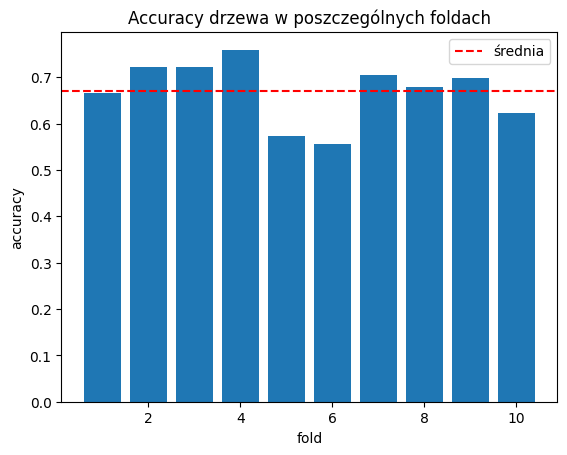

In [6]:
print(f"Accuracy w 10-krotnej CV: średnia = {cv_acc.mean():.3f}, std = {cv_acc.std():.3f}")

plt.bar(range(1, 11), cv_acc)
plt.axhline(cv_acc.mean(), color="red", linestyle="--", label="średnia")
plt.xlabel("fold")
plt.ylabel("accuracy")
plt.title("Accuracy drzewa w poszczególnych foldach")
plt.legend()
plt.show()

---
##### *Zadanie 3*

Na zbiorze treningowym wykonaj 100 powtórzeń 10-krotnej walidacji krzyżowej dla drzewa, używając miary `roc_auc`. Podaj średnią, odchylenie standardowe i narysuj rozkład wyników.


In [7]:
rkf = RepeatedKFold(n_splits=10, n_repeats=100, random_state=123)

cv_auc = cross_val_score(
    tree.DecisionTreeClassifier(random_state=123),
    X_cv_train, y_cv_train,
    cv=rkf,
    scoring="roc_auc",
    n_jobs=-1
)

print(f"Liczba wyników: {len(cv_auc)}")
print(f"ROC AUC: średnia = {cv_auc.mean():.3f}, std = {cv_auc.std():.3f}")

Liczba wyników: 1000
ROC AUC: średnia = 0.651, std = 0.069


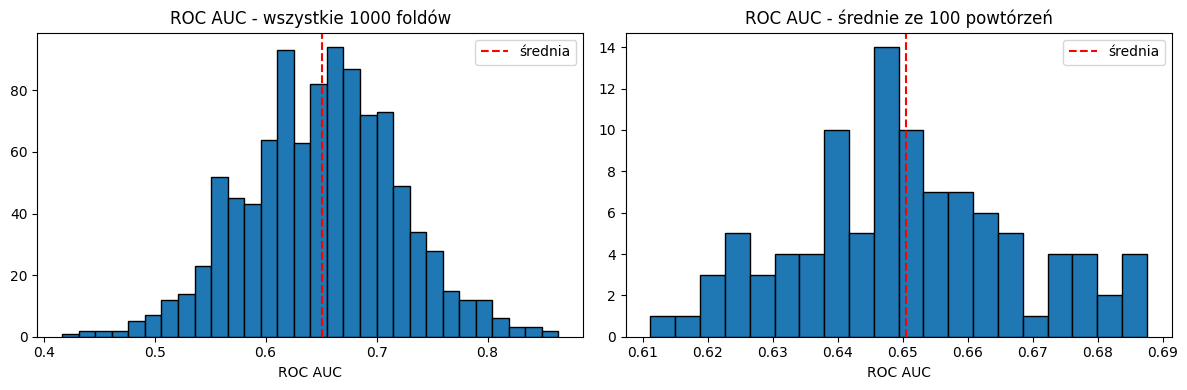

std pojedynczych foldów: 0.069
std średnich z powtórzeń: 0.017


In [ ]:
# średnia z każdego z 100 powtórzeń (kolejne bloki po 10 foldów)
auc_per_repeat = cv_auc.reshape(100, 10).mean(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(cv_auc, bins=30, edgecolor="black")
axes[0].axvline(cv_auc.mean(), color="red", linestyle="--", label="średnia")
axes[0].set_title("ROC AUC - wszystkie 1000 foldów")
axes[0].set_xlabel("ROC AUC")
axes[0].legend()

axes[1].hist(auc_per_repeat, bins=20, edgecolor="black")
axes[1].axvline(auc_per_repeat.mean(), color="red", linestyle="--", label="średnia")
axes[1].set_title("ROC AUC - średnie ze 100 powtórzeń")
axes[1].set_xlabel("ROC AUC")
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"std pojedynczych foldów: {cv_auc.std():.3f}")
print(f"std średnich z powtórzeń: {auc_per_repeat.std():.3f}")

---
##### *Zadanie 4*

Dla danych `pima` zbadaj zachowanie hiperparametru `max_leaf_nodes` drzewa klasyfikacyjnego w zakresie od 2 do 30. Na danych treningowych i w 5-krotnej CV oblicz `accuracy`, `precision` i `roc_auc`. Przygotuj wizualizację, wybierz wartość według `roc_auc` z CV, a następnie raz oceń wybrany model na zbiorze testowym.

> **Uwaga.** Hiperparametr wybieramy wyłącznie na podstawie wyniku walidacji krzyżowej. Zbiór testowy służy tylko do końcowej oceny wybranego modelu.


In [15]:
leaf_grid = range(2, 31)
kf5 = KFold(n_splits=5, shuffle=True, random_state=123)

rows = []
for m in leaf_grid:
    model = tree.DecisionTreeClassifier(max_leaf_nodes=m, random_state=123)

    model.fit(X_cv_train, y_cv_train)
    pred_tr = model.predict(X_cv_train)
    proba_tr = model.predict_proba(X_cv_train)[:, 1]

    cv_acc  = cross_val_score(model, X_cv_train, y_cv_train, cv=kf5, scoring="accuracy")
    cv_prec = cross_val_score(model, X_cv_train, y_cv_train, cv=kf5, scoring="precision")
    cv_auc  = cross_val_score(model, X_cv_train, y_cv_train, cv=kf5, scoring="roc_auc")

    rows.append({
        "max_leaf_nodes": m,
        "train_accuracy":  accuracy_score(y_cv_train, pred_tr),
        "train_precision": precision_score(y_cv_train, pred_tr, zero_division=0),
        "train_roc_auc":   roc_auc_score(y_cv_train, proba_tr),
        "cv_accuracy":  cv_acc.mean(),
        "cv_precision": cv_prec.mean(),
        "cv_roc_auc":   cv_auc.mean(),
        "cv_roc_auc_std": cv_auc.std(),
    })

results = pd.DataFrame(rows).set_index("max_leaf_nodes")
results.round(3)


,train_accuracy,train_precision,train_roc_auc,cv_accuracy,cv_precision,cv_roc_auc,cv_roc_auc_std
max_leaf_nodes,,,,,,,
2,0.745,0.765,0.646,0.704,0.699,0.611,0.032
3,0.745,0.765,0.737,0.724,0.742,0.697,0.047
4,0.745,0.765,0.803,0.702,0.683,0.746,0.072
5,0.778,0.645,0.824,0.752,0.629,0.768,0.069
6,0.795,0.680,0.830,0.747,0.640,0.764,0.046
7,0.795,0.680,0.846,0.745,0.635,0.758,0.042
8,0.803,0.695,0.851,0.737,0.623,0.762,0.050
9,0.803,0.695,0.857,0.739,0.627,0.760,0.052
10,0.812,0.714,0.864,0.724,0.590,0.747,0.062


In [18]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer, roc_curve

leaf_grid = list(range(2, 31))
scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "roc_auc": "roc_auc",
}

records = []
for m in leaf_grid:
    cv_res = cross_validate(
        tree.DecisionTreeClassifier(max_leaf_nodes=m, random_state=123),
        X_cv_train, y_cv_train,
        cv=kf5, scoring=scoring, return_train_score=True, n_jobs=-1,
    )
    for split in ["train", "test"]:
        for metric in scoring:
            for fold, s in enumerate(cv_res[f"{split}_{metric}"]):
                records.append({"max_leaf_nodes": m, "split": split,
                                "metric": metric, "fold": fold, "score": s})

cv_long = pd.DataFrame(records)
summary = (cv_long.groupby(["metric", "split", "max_leaf_nodes"])["score"]
           .agg(["mean", "std"]).reset_index())

auc_cv = summary.query("metric == 'roc_auc' and split == 'test'").set_index("max_leaf_nodes")
best_m = auc_cv["mean"].idxmax()
print(f"Najlepsze max_leaf_nodes wg CV ROC AUC: {best_m} "
      f"(AUC = {auc_cv.loc[best_m, 'mean']:.3f} ± {auc_cv.loc[best_m, 'std']:.3f})")

Najlepsze max_leaf_nodes wg CV ROC AUC: 5 (AUC = 0.768 ± 0.077)


In [20]:
%pip install nbformat plotly

  Using cached nbformat-5.11.1-py3-none-any.whl.metadata (3.7 kB)
  Using cached fastjsonschema-2.22.2-py3-none-any.whl.metadata (2.1 kB)
  Using cached jsonschema-4.26.0-py3-none-any.whl.metadata (7.6 kB)
  Using cached attrs-26.1.0-py3-none-any.whl.metadata (8.8 kB)
  Using cached jsonschema_specifications-2025.9.1-py3-none-any.whl.metadata (2.9 kB)
  Using cached referencing-0.37.0-py3-none-any.whl.metadata (2.8 kB)
Using cached nbformat-5.11.1-py3-none-any.whl (79 kB)
Using cached fastjsonschema-2.22.2-py3-none-any.whl (27 kB)
Using cached jsonschema-4.26.0-py3-none-any.whl (90 kB)
Using cached attrs-26.1.0-py3-none-any.whl (67 kB)
Using cached jsonschema_specifications-2025.9.1-py3-none-any.whl (18 kB)
Using cached referencing-0.37.0-py3-none-any.whl (26 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [nbformat]6/7 [nbformat]
Note: you may need to restart the kernel to use updated packages.


In [22]:
C_CV, C_TR = "#2a78d6", "#eb6834"
BAND_CV, BAND_TR = "rgba(42,120,214,0.15)", "rgba(235,104,52,0.12)"
titles = {"accuracy": "Accuracy", "precision": "Precision", "roc_auc": "ROC AUC"}

fig = make_subplots(rows=1, cols=3, subplot_titles=list(titles.values()),
                    horizontal_spacing=0.07)

for col, metric in enumerate(titles, start=1):
    for split, name, color, band, dash in [
        ("train", "trening (foldy)", C_TR, BAND_TR, "dash"),
        ("test",  "walidacja (5-krotna CV)", C_CV, BAND_CV, "solid"),
    ]:
        d = summary.query("metric == @metric and split == @split")
        x, mu, sd = d["max_leaf_nodes"], d["mean"], d["std"]
        # pasmo ±1 std: górna krawędź, potem dolna z wypełnieniem do poprzedniej
        fig.add_trace(go.Scatter(x=x, y=mu + sd, mode="lines", line_width=0,
                                 showlegend=False, hoverinfo="skip", legendgroup=split),
                      row=1, col=col)
        fig.add_trace(go.Scatter(x=x, y=mu - sd, mode="lines", line_width=0,
                                 fill="tonexty", fillcolor=band,
                                 showlegend=False, hoverinfo="skip", legendgroup=split),
                      row=1, col=col)
        fig.add_trace(go.Scatter(
            x=x, y=mu, mode="lines+markers", name=name, legendgroup=split,
            showlegend=(col == 1),
            line=dict(color=color, width=2, dash=dash), marker=dict(size=6),
            customdata=sd,
            hovertemplate=f"{name}: %{{y:.3f}} ± %{{customdata:.3f}}<extra></extra>",
        ), row=1, col=col)
    fig.add_vline(x=best_m, line=dict(color="#52514e", width=1, dash="dot"), row=1, col=col)

fig.add_annotation(x=best_m, y=0.03, xref="x3", yref="y3 domain", xanchor="left", xshift=4,
                   text=f"wybrane: {best_m}", showarrow=False,
                   font=dict(size=11, color="#52514e"))
fig.update_xaxes(title_text="max_leaf_nodes", dtick=4, showgrid=False)
fig.update_yaxes(gridcolor="rgba(0,0,0,0.07)", zeroline=False)
fig.update_layout(
    template="plotly_white", height=430, hovermode="x unified",
    title=dict(text="Drzewo decyzyjne: jakość vs liczba liści "
                    "<span style='font-size:13px;color:#52514e'>(średnia ± 1 std z 5 foldów)</span>",
               x=0.01),
    legend=dict(orientation="h", y=-0.2, x=0.5, xanchor="center"),
    margin=dict(t=80, b=90, l=50, r=20),
)
fig.show()

ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

In [ ]:
msl_grid = [1, 2, 5, 10, 15, 25, 40]
Z = np.empty((len(msl_grid), len(leaf_grid)))
for i, msl in enumerate(msl_grid):
    for j, m in enumerate(leaf_grid):
        Z[i, j] = cross_val_score(
            tree.DecisionTreeClassifier(max_leaf_nodes=m, min_samples_leaf=msl, random_state=123),
            X_cv_train, y_cv_train, cv=kf5, scoring="roc_auc", n_jobs=-1,
        ).mean()

i_best, j_best = np.unravel_index(Z.argmax(), Z.shape)

fig3d = go.Figure()
fig3d.add_trace(go.Surface(
    x=leaf_grid, y=msl_grid, z=Z, colorscale="Blues", opacity=0.95,
    colorbar=dict(title="CV AUC", thickness=14, len=0.6, x=0.92),
    contours=dict(z=dict(show=True, usecolormap=True, project_z=True, width=1)),
    hovertemplate="max_leaf_nodes = %{x}<br>min_samples_leaf = %{y}"
                  "<br>CV AUC = %{z:.3f}<extra></extra>",
))
fig3d.add_trace(go.Scatter3d(   # przekrój z zadania 4 (min_samples_leaf = 1, domyślne)
    x=leaf_grid, y=[1] * len(leaf_grid), z=Z[0], mode="lines",
    line=dict(color="#0b0b0b", width=6), name="przekrój z zad. 4 (min_samples_leaf=1)",
    hoverinfo="skip",
))
fig3d.add_trace(go.Scatter3d(
    x=[leaf_grid[j_best]], y=[msl_grid[i_best]], z=[Z[i_best, j_best]],
    mode="markers+text", marker=dict(size=7, color="#eb6834", line=dict(color="white", width=2)),
    text=[f"max {Z[i_best, j_best]:.3f}"], textposition="top center",
    name=f"maksimum: leaves={leaf_grid[j_best]}, msl={msl_grid[i_best]}",
))
fig3d.update_layout(
    template="plotly_white", height=620,
    title=dict(text="CV ROC AUC na siatce dwóch hiperparametrów", x=0.01),
    scene=dict(
        xaxis_title="max_leaf_nodes", yaxis_title="min_samples_leaf", zaxis_title="CV ROC AUC",
        camera=dict(eye=dict(x=1.35, y=-1.35, z=0.7)),
        aspectmode="manual", aspectratio=dict(x=1.3, y=1, z=0.6),
    ),
    legend=dict(orientation="h", y=0.02, x=0.5, xanchor="center"),
    margin=dict(t=60, b=10, l=10, r=10),
)
fig3d.show()

In [ ]:
final_tree = tree.DecisionTreeClassifier(max_leaf_nodes=best_m, random_state=123)
final_tree.fit(X_cv_train, y_cv_train)
proba_te = final_tree.predict_proba(X_cv_test)[:, 1]
fpr, tpr, thr = roc_curve(y_cv_test, proba_te)
auc_te = roc_auc_score(y_cv_test, proba_te)

figroc = go.Figure()
figroc.add_trace(go.Scatter(x=[0, 1], y=[0, 1], mode="lines", name="losowy klasyfikator",
                            line=dict(color="#9a9893", dash="dash", width=1), hoverinfo="skip"))
figroc.add_trace(go.Scatter(
    x=fpr, y=tpr, mode="lines+markers", name=f"drzewo, {best_m} liści (AUC = {auc_te:.3f})",
    line=dict(color=C_CV, width=2), marker=dict(size=8),
    fill="tozeroy", fillcolor=BAND_CV,
    customdata=np.clip(thr, 0, 1),
    hovertemplate="próg ≥ %{customdata:.3f}<br>FPR = %{x:.3f}<br>TPR = %{y:.3f}<extra></extra>",
))
figroc.update_layout(
    template="plotly_white", height=520, width=560,
    title=dict(text="Krzywa ROC na zbiorze testowym", x=0.01),
    xaxis=dict(title="False Positive Rate", range=[0, 1], constrain="domain"),
    yaxis=dict(title="True Positive Rate", range=[0, 1.02], scaleanchor="x", scaleratio=1),
    legend=dict(x=0.98, y=0.04, xanchor="right", bgcolor="rgba(255,255,255,0.8)"),
    margin=dict(t=60, b=50, l=60, r=20),
)
figroc.show()

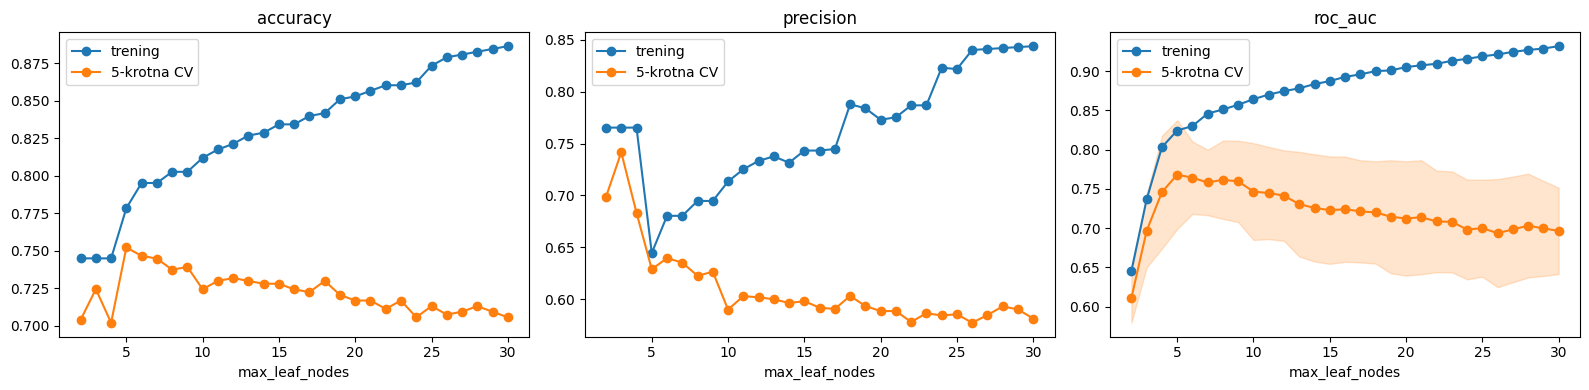

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharex=True)

for ax, metric in zip(axes, ["accuracy", "precision", "roc_auc"]):
    ax.plot(results.index, results[f"train_{metric}"], marker="o", label="trening")
    ax.plot(results.index, results[f"cv_{metric}"], marker="o", label="5-krotna CV")
    ax.set_title(metric)
    ax.set_xlabel("max_leaf_nodes")
    ax.legend()

# pasmo +-1 std dla AUC w CV
axes[2].fill_between(
    results.index,
    results["cv_roc_auc"] - results["cv_roc_auc_std"],
    results["cv_roc_auc"] + results["cv_roc_auc_std"],
    alpha=0.2, color="tab:orange"
)

plt.tight_layout()
plt.show()

In [11]:
best_m = results["cv_roc_auc"].idxmax()
print(f"Wybrane max_leaf_nodes = {best_m}, ROC AUC w CV = {results.loc[best_m, 'cv_roc_auc']:.3f}")

final_tree = tree.DecisionTreeClassifier(max_leaf_nodes=best_m, random_state=123)
final_tree.fit(X_cv_train, y_cv_train)

pred_te = final_tree.predict(X_cv_test)
proba_te = final_tree.predict_proba(X_cv_test)[:, 1]

print(f"Test accuracy:  {accuracy_score(y_cv_test, pred_te):.3f}")
print(f"Test precision: {precision_score(y_cv_test, pred_te):.3f}")
print(f"Test ROC AUC:   {roc_auc_score(y_cv_test, proba_te):.3f}")

Wybrane max_leaf_nodes = 5, ROC AUC w CV = 0.768
Test accuracy:  0.753
Test precision: 0.657
Test ROC AUC:   0.809


### 2. Model regresji liniowej

Równanie modelu (w postaci macierzowej)

$$Y = X \beta + \epsilon$$

Gdzie:

- $Y$ – wektor zmiennej objaśnianej (wymiar $n \times 1$)

- $X$ – macierz cech / zmiennych objaśniających (wymiar $n \times (p+1)$, gdzie pierwsza kolumna to same jedynki dla wyrazu wolnego)

- $\beta$ – wektor nieznanych parametrów / współczynników regresji (wymiar $(p+1) \times 1$)

- $\epsilon$ – wektor składników losowych / błędów (wymiar $n \times 1$)

Kluczowe założenia modelu

- wartość oczekiwana błędu: $E(\epsilon) = 0$

- homoskedastyczność (stała wariancja błędów): $Var(\epsilon \vert{} X) = \sigma^2 I$ (gdzie $I$ to macierz jednostkowa)

- brak współliniowości: macierz $X$ ma pełny rząd kolumnowy, co oznacza, że macierz $X^T X$ jest odwracalna


Współczynniki $\beta$ wyznacza się, minimalizując sumę kwadratów reszt ($RSS$):

$$RSS = \epsilon^T \epsilon = (Y - X\beta)^T (Y - X\beta) \to \min_{\beta}.$$

Rozwiązanie tego problemu prowadzi do wzoru analitycznego na estymator współczynników $\hat{\beta}$:$$\hat{\beta} = (X^T X)^{-1} X^T Y.$$

Przewidywane wartości zmiennej objaśnianej ($\hat{Y}$) dla nowych danych oblicza się jako:$$\hat{Y} = X\hat{\beta}.$$

In [ ]:
# Wczytujemy zbiór danych do regresji liniowej
hills = pd.read_csv("hills.csv")

Zbiór danych dotyczący szkockich biegów górskich.
- dist – dystans trasy w milach,

- climb – suma przewyższenia w stópach,

- time – rekordowy czas (męski) w godzinach

> https://search.r-project.org/CRAN/refmans/DAAG/html/hills.html

-----
##### *Zadanie 5*

Dla danych `hills.csv`:

a) Narysuj wykres rozproszenia zmiennej *time* od *dist* oraz *time* od *climb*.

b) Oblicz współczynnik korelacji.


#### Budujemy model regresji liniowej dla pary zmiennych dist i time

-----
##### *Zadanie 6*

Na wykresie rozproszenia dla `dist` i `time` zaznacz wyestymowaną prostą z modelu liniowego.

-----
##### *Zadanie 7*

Zbuduj model regresji liniowej opisujący zależność *time* od *climb*, wyznacz współczynniki, narysuj wykres rozproszenia i zaznacz wyestymowaną prostą.

### 3. Model regresji logistycznej

W modelu regresji liniowej, predykcja jest ciągłą wartością (np. cena domu, wzrost), a model wygląda następująco:

$$\hat{y} = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_n x_n$$
$\hat{y}$ to przewidywana ciągła wartość.

$\beta_i$ to współczynniki (wagi) modelu.

$x_i$ to zmienne niezależne (cechy).

Ponieważ wartości prognozowane przez model regresji liniowej są rzeczywiste (od $-\infty$ do $+\infty$), a naszym celem jest klasyfikacja, stosujemy funkcję logistyczną jako przekształcenie.

$$\sigma(z) = \frac{1}{1 + e^{-z}}$$
Gdzie $z$ to liniowa: $z = \beta_0 + \beta_1 x_1 + \dots + \beta_n x_n$.

Podstawiając predykcję liniową ($z$) do funkcji logistycznej, otrzymujemy model regresji logistycznej, który zwraca prawdopodobieństwo $P(Y=1|X)$:$$P(Y=1|X) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 x_1 + \dots + \beta_n x_n)}}$$

W regresji logistycznej istotne jest pojęcie logitu, który jest logarytmem naturalnym ze stosunku szans:$$\text{Logit} = \ln\left(\frac{P(Y=1|X)}{1 - P(Y=1|X)}\right)$$Zauważ, że logit jest równy liniowej kombinacji cech (wynikowi regresji liniowej):$$\ln\left(\frac{P(Y=1|X)}{1 - P(Y=1|X)}\right) = \beta_0 + \beta_1 x_1 + \dots + \beta_n x_n$$To jest powód, dla którego model nazywa się regresją logistyczną - ponieważ regresja jest wykonywana na logarytmie szans (logits).

-----
##### *Zadanie 8*

Przygotuj zbiór danych `SAheart.data` do dalszej pracy.


In [3]:
SAheart = pd.read_csv("SAheart.data")

-----
##### *Zadanie 9*

a) Dopasuj model regresji logistycznej do danych `SAheart.data`.

b) Oblicz prawdopodobieństwa przynależności do klasy 1 dla zbioru testowego.

c) Dokonaj predykcji dla obserwacji o wartościach `sbp = 127`, `age = 30`, `alcohol = 0`, `obesity = 25`, `typea = 49`, `famhist = 'Present'`, `tobacco = 0`, `ldl = 4.44`, `adiposity = 18`.

d) Oceń model na zbiorze testowym za pomocą `accuracy` i ROC AUC.


-----
##### *Zadanie 10*

Weźmy pod uwagę dane `earthquake.txt`, które dotyczą klasyfikacji wstrząsów (zmienna *popn*). Zmienne objaśniające to zmienne *body* i *surface* (zmienne sejsmologiczne).

a) Wykonaj wykres dla zmiennych *body* i *surface* z zaznaczeniem przynależności do klas.

b) Dopasuj model regresji logistycznej.

c) Zinterpretuj współczynniki modelu.

> **Uwaga.** Zbiór `earthquake` ma tylko 29 obserwacji. W tym przykładzie dopasowujemy model do całych danych wyłącznie po to, aby zilustrować granicę decyzyjną i interpretację współczynników — nie jest to ocena jakości modelu na nowych danych.


In [24]:
earthquake = pd.read_csv("earthquake.txt", sep=" ")

### 4. Wprowadzenie do `Pipeline`

W praktyce modelowanie zwykle obejmuje więcej niż samo dopasowanie klasyfikatora: na przykład uzupełnianie braków, kodowanie kategorii albo skalowanie zmiennych. Obiekt `Pipeline` łączy takie kroki w jeden estymator. Dzięki temu podczas `fit` transformacje są dopasowywane wyłącznie do zbioru treningowego, a następnie automatycznie stosowane do nowych danych.

W następnym laboratorium wykorzystamy `Pipeline` do pełnego przygotowania danych o różnych typach i z brakującymi wartościami.


#### Przykład: regresja logistyczna w `Pipeline`

Poniżej łączymy standaryzację i regresję logistyczną w jeden obiekt. Po wywołaniu `fit` skaler jest dopasowywany wyłącznie do danych treningowych, a następnie te same kroki są automatycznie stosowane przy `predict` i `predict_proba`.


In [ ]:
logistic_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(C=np.inf, max_iter=300)),
])
logistic_pipeline.fit(X_train, y_train)

pipeline_probabilities = logistic_pipeline.predict_proba(X_test)[:, 1]
print("Accuracy pipeline'u na zbiorze testowym:",
      round(logistic_pipeline.score(X_test, y_test), 3))
print("Pierwsze prawdopodobieństwa:", np.round(pipeline_probabilities[:5], 3))
